Multi-Factor Attrition Analysis and Employee Engagement Profiling

The Dataset Used: IBM HR Analytics Dataset

Cell No 1: That we imported the Dataset from the Kaggle.

In [ ]:
import kagglehub

path = kagglehub.dataset_download("pavansubhasht/ibm-hr-analytics-attrition-dataset")

print("Dataset Path:", path)

Using Colab cache for faster access to the 'ibm-hr-analytics-attrition-dataset' dataset.
Dataset Path: /kaggle/input/ibm-hr-analytics-attrition-dataset


Cell No 2: To display all files and folders inside a directory and its subdirectories.

In [ ]:
import os

for root, dirs, files in os.walk(path):
    for file in files:
        print(os.path.join(root, file))

/kaggle/input/ibm-hr-analytics-attrition-dataset/WA_Fn-UseC_-HR-Employee-Attrition.csv


Cell No 3: Install & Import Libraries

In [ ]:
!pip install kagglehub seaborn

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency, f_oneway
from sklearn.preprocessing import LabelEncoder

sns.set_style("whitegrid")

Cell No 4:To import the dataset into Python for analysis and Displays the first 5 rows of the dataset.

In [ ]:
df = pd.read_csv(path + "/WA_Fn-UseC_-HR-Employee-Attrition.csv")

df.head()

,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


Cell No 5: Displays the total number of rows and columns in the dataset.

In [ ]:
print("Rows and Columns:", df.shape)

Rows and Columns: (1470, 35)


Cell No 6: Displays the concise summary of the dataset.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1470 non-null   int64 
 1   Attrition                 1470 non-null   object
 2   BusinessTravel            1470 non-null   object
 3   DailyRate                 1470 non-null   int64 
 4   Department                1470 non-null   object
 5   DistanceFromHome          1470 non-null   int64 
 6   Education                 1470 non-null   int64 
 7   EducationField            1470 non-null   object
 8   EmployeeCount             1470 non-null   int64 
 9   EmployeeNumber            1470 non-null   int64 
 10  EnvironmentSatisfaction   1470 non-null   int64 
 11  Gender                    1470 non-null   object
 12  HourlyRate                1470 non-null   int64 
 13  JobInvolvement            1470 non-null   int64 
 14  JobLevel                

Cell No 7: Counts the number of missing values to identify data quality issues in the dataset.

In [ ]:
missing_values = df.isnull().sum()

print("Missing Values Count:")
print(missing_values)

Missing Values Count:
Age                         0
Attrition                   0
BusinessTravel              0
DailyRate                   0
Department                  0
DistanceFromHome            0
Education                   0
EducationField              0
EmployeeCount               0
EmployeeNumber              0
EnvironmentSatisfaction     0
Gender                      0
HourlyRate                  0
JobInvolvement              0
JobLevel                    0
JobRole                     0
JobSatisfaction             0
MaritalStatus               0
MonthlyIncome               0
MonthlyRate                 0
NumCompaniesWorked          0
Over18                      0
OverTime                    0
PercentSalaryHike           0
PerformanceRating           0
RelationshipSatisfaction    0
StandardHours               0
StockOptionLevel            0
TotalWorkingYears           0
TrainingTimesLastYear       0
WorkLifeBalance             0
YearsAtCompany              0
YearsInCurrentRole

Cell No 8: Displays the total number of missing values.

In [ ]:
print("Total Missing Values:", df.isnull().sum().sum())

Total Missing Values: 0


Cell No 9: Counts duplicate records in the dataset.

In [ ]:
duplicate_count = df.duplicated().sum()

print("Duplicate Records:", duplicate_count)

Duplicate Records: 0


Cell No 10: Visualizing the distribution of employee attrition, showing how many employees stayed and how many left the organization by using the the bar chart.

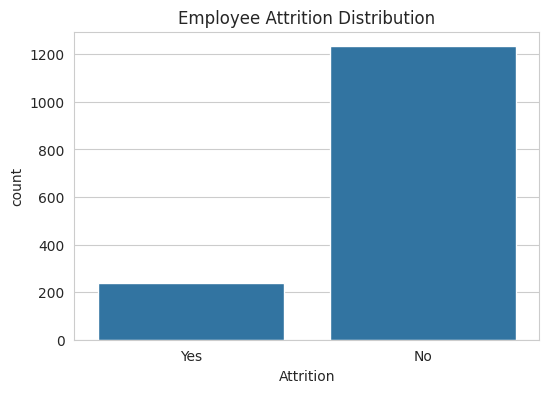

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='Attrition', data=df)
plt.title('Employee Attrition Distribution')
plt.show()

This chart shows:

1200 "No"
270 "Yes"

Cell No 11: Visualizing the distribution of employees by gender, helping analyze the workforce composition by using the Bar Chart.

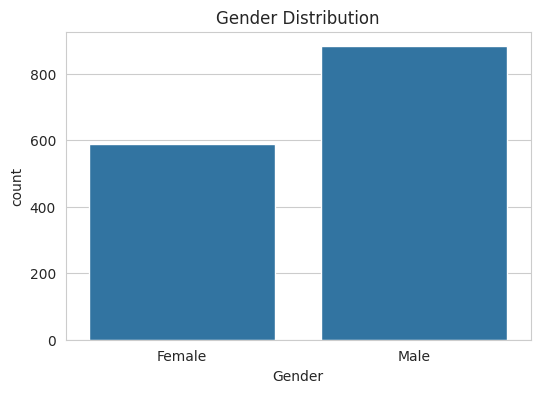

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='Gender', data=df)
plt.title('Gender Distribution')
plt.show()

This chart shows:

Male = 882 employees
Female = 588 employees

Cell No 12: To display the distribution of employees across different departments, helping analyze workforce allocation within the organization.

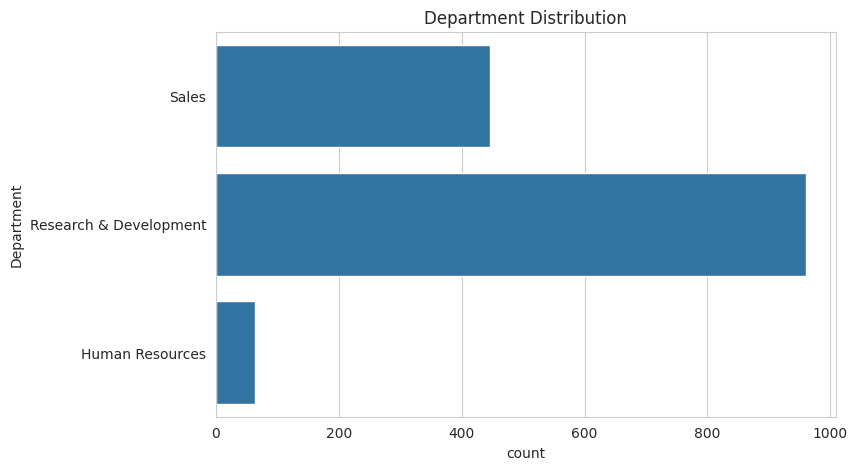

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(y='Department', data=df)
plt.title('Department Distribution')
plt.show()

This chart shows:

Research & Development = 961 employees
Sales = 446 employees
Human Resources = 63 employees

Cell No 13: Visualizing the distribution of employees' monthly income, helping identify salary patterns, spread, and potential outliers."

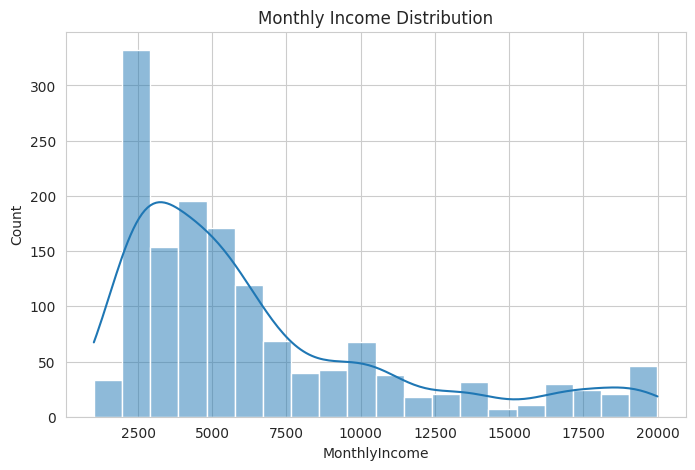

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(df['MonthlyIncome'], bins=20, kde=True)
plt.title('Monthly Income Distribution')
plt.show()

Cell No 14 & 15: Univariate Analysis

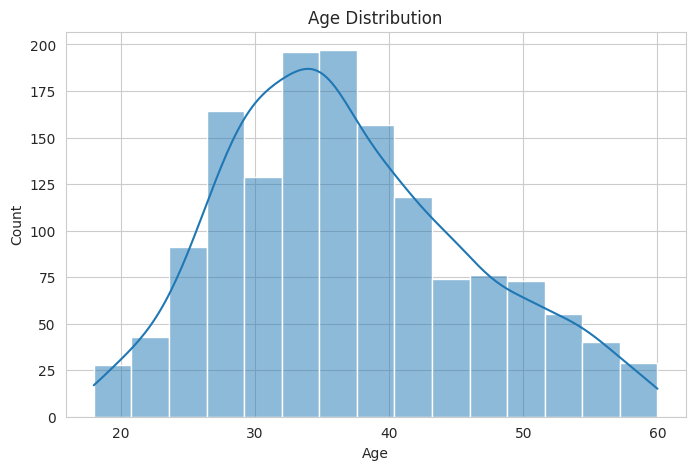

In [ ]:
# Univariate Analysis

plt.figure(figsize=(8,5))
sns.histplot(df['Age'], bins=15, kde=True)
plt.title('Age Distribution')
plt.show()



*   If most employees are between 30 and 40 years, the histogram will show higher
bars in that range.
*   If very few employees are much younger or older, the bars at the ends will be lower.




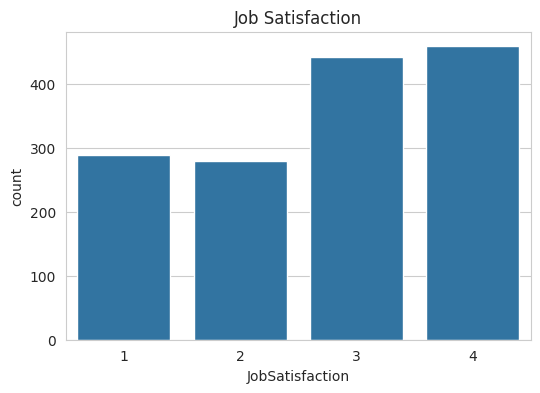

In [ ]:
plt.figure(figsize=(6,4))
sns.countplot(x='JobSatisfaction', data=df)
plt.title('Job Satisfaction')
plt.show()



*   If Level 4 has the highest count, most employees are very satisfied with their jobs.

*   If Level 1 has a high count, it may indicate employee dissatisfaction, which could contribute to attrition.



Cell No 16 & 17: Bivariate Analysis

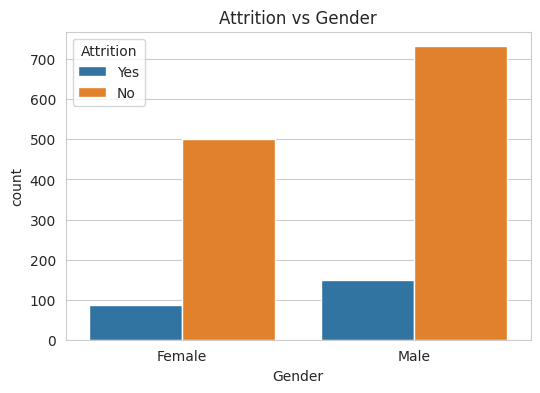

In [ ]:
# Bivariate Analysis

plt.figure(figsize=(6,4))
sns.countplot(x='Gender', hue='Attrition', data=df)
plt.title('Attrition vs Gender')
plt.show()



*   If the "Yes" bar is higher for males than females, more male employees left the company.

*   If both genders have similar counts, gender may not significantly influence attrition.



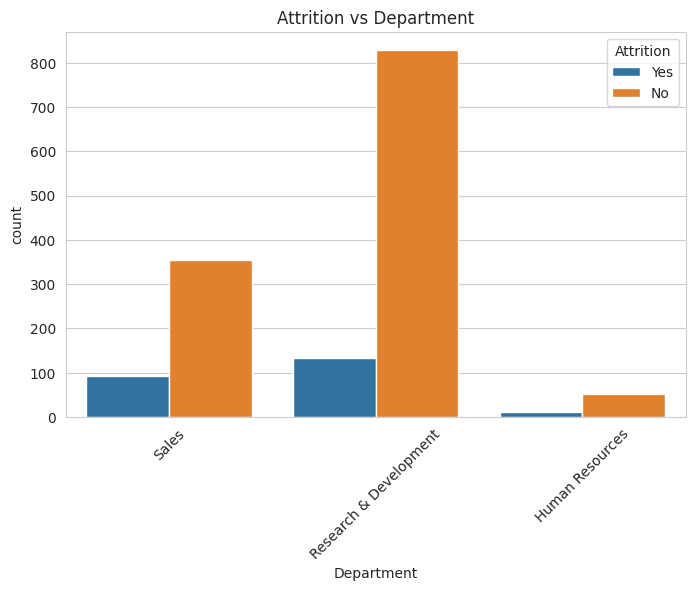

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(x='Department', hue='Attrition', data=df)
plt.xticks(rotation=45)
plt.title('Attrition vs Department')
plt.show()



*   If the Sales department has a higher "Yes" count, it indicates more employees are leaving Sales.

*   If Research & Development has a lower attrition count, employee retention may be better in that department.



Cell No 18 & 19: Multivariate Analysis


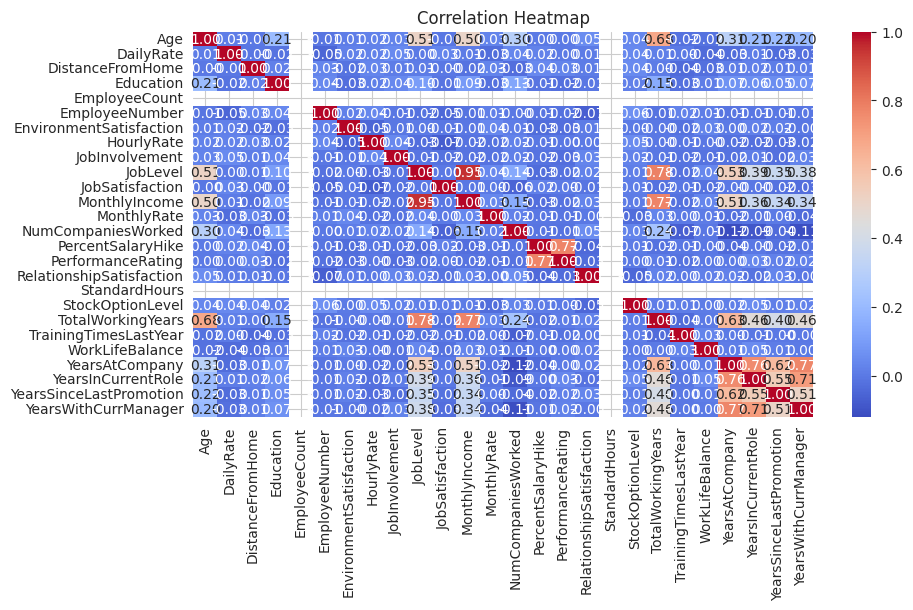

In [ ]:
# Multivariate Analysis

numeric_df = df.select_dtypes(include=['int64','float64'])

plt.figure(figsize=(10,5))
sns.heatmap(numeric_df.corr(),
            annot=True,
            fmt='.2f',
            cmap='coolwarm')

plt.title('Correlation Heatmap')
plt.show()

To visualize and analyze relationships between numerical variables in the dataset.


*   Correlation close to +1 → Both variables increase together.
*   Correlation close to -1 → One variable increases while the other decreases.
*   Correlation close to 0 → Little or no relationship.





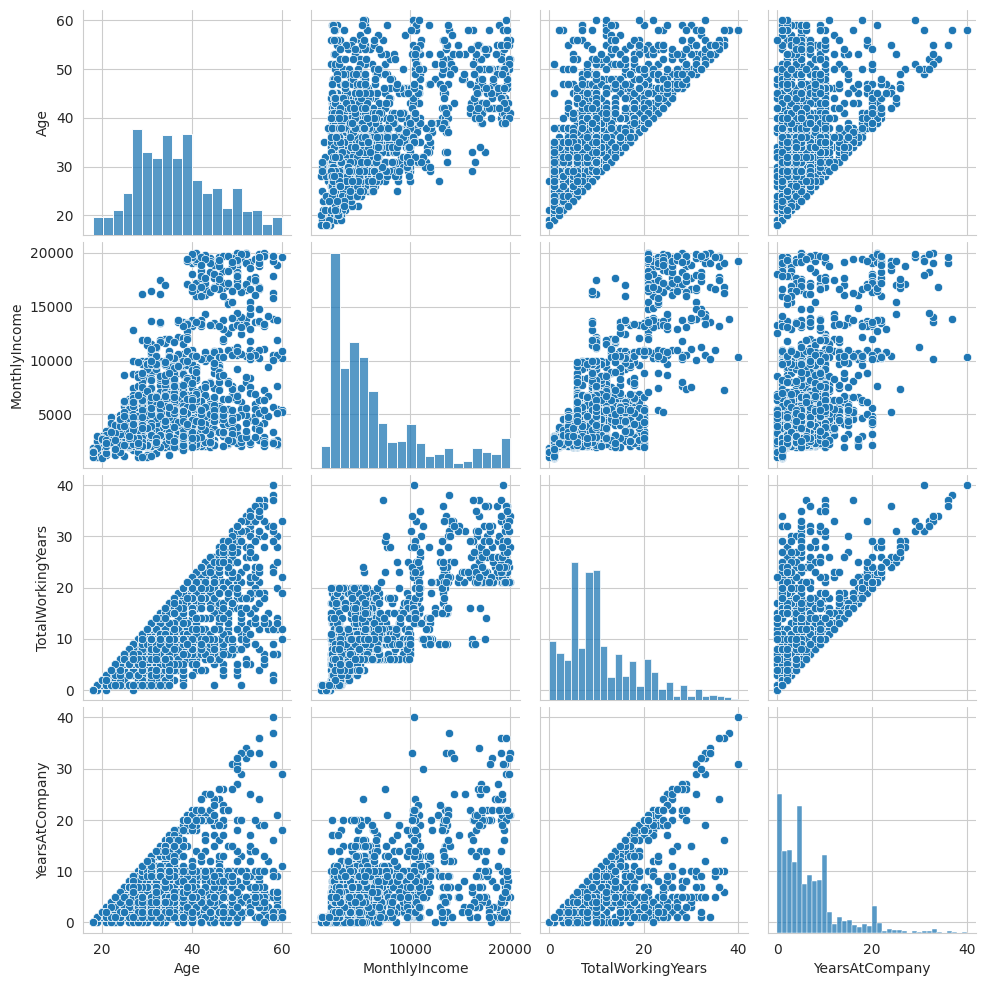

In [ ]:
selected_columns = ['Age',
                    'MonthlyIncome',
         s           'TotalWorkingYears',
                    'YearsAtCompany']

sns.pairplot(df[selected_columns])
plt.show()

To visualize the relationships and distributions of key numerical variables, helping identify patterns, correlations, and outliers in the dataset.

*   If TotalWorkingYears increases along with MonthlyIncome, it suggests that employees with more experience tend to earn higher salaries.

*   If Age and YearsAtCompany show an upward trend, older employees may have longer tenure.



**Final Report:**

Step 1: Load the Dataset
Imported the IBM HR Analytics dataset using Pandas.
Stored the dataset in a DataFrame for analysis.

Step 2: Data Understanding
Viewed the first few records using df.head().
Checked the dataset dimensions using df.shape.
Examined column names, data types, and non-null values using df.info().

Step 3: Missing Value Analysis
Checked missing values in each column using df.isnull().sum().
Calculated total missing values in the dataset.
Result: No missing values were found.

Step 4: Duplicate Detection
Identified duplicate records using df.duplicated().sum().
Result: No duplicate records were found.

Step 5: Univariate Analysis
Visualized Employee Attrition Distribution.
Visualized Gender Distribution.
Visualized Department Distribution.
Analyzed Age Distribution using a histogram.
Analyzed Monthly Income Distribution using a histogram.
Visualized Job Satisfaction levels.

Step 6: Bivariate Analysis
Analyzed Attrition vs Gender using a count plot.
Analyzed Attrition vs Department using a count plot.

Step 7: Correlation Analysis
Selected numerical columns.
Generated a correlation heatmap.
Examined relationships between numerical variables.

Step 8: Pair Plot Analysis
Selected Age, Monthly Income, Total Working Years, and Years at Company.
Generated a pair plot to identify patterns and relationships among key numerical features.

Step 9: Key Findings
No missing values were present.
No duplicate records were found.
Most employees remained in the company.
Research & Development had the highest number of employees.
Monthly income generally increased with experience.
Job satisfaction levels were mostly moderate to high.

Step 10: Conclusion
Successfully performed Exploratory Data Analysis (EDA) on the IBM HR Analytics dataset.
Identified important patterns related to employee demographics, income, satisfaction, and attrition.
The analysis provided useful insights for understanding employee retention and workforce behavior.
